In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 08 · Final Segmentation

In [2]:
json.loads((ROOT / '07_customer_segmentation/results/final_model.json').read_text())

{'winner': 'E2-rfm-log-standard-kmeans-k4',
 'segments': {'S1': 'At Risk',
  'S2': 'Hibernating',
  'S3': 'New Customers',
  'S4': 'Loyal Customers'},
 'colors': {'At Risk': '#D9653B',
  'Hibernating': '#C266C0',
  'New Customers': '#139C85',
  'Loyal Customers': '#3558D4'},
 'churn_threshold_days': 278,
 'snapshot_prev': '2018-03-01',
 'analysis_date': '2018-09-01'}

In [3]:
p = pd.read_csv(ROOT / '07_customer_segmentation/results/segment_profile.csv')
p[['segment_id','segment_name','customers','customer_share','revenue_contribution','avg_recency_days','avg_frequency','avg_monetary','avg_order_value','repeat_rate','churn_rate','avg_review_score','late_delivery_share','avg_installments','avg_predicted_clv_12m','segment_growth_rate']].round(3)

,segment_id,segment_name,customers,customer_share,revenue_contribution,avg_recency_days,avg_frequency,avg_monetary,avg_order_value,repeat_rate,churn_rate,avg_review_score,late_delivery_share,avg_installments,avg_predicted_clv_12m,segment_growth_rate
0,S1,At Risk,31608,0.339,0.612,274.947,1.000,297.681,297.681,0.0,0.437,4.043,0.084,4.013,1.977,1.084
1,S2,Hibernating,41746,0.448,0.186,291.439,1.000,68.315,68.315,0.0,0.482,4.170,0.069,2.153,1.893,1.117
2,S3,New Customers,16961,0.182,0.146,47.036,1.000,132.751,132.751,0.0,0.000,4.313,0.040,2.674,3.789,-0.096
3,S4,Loyal Customers,2789,0.030,0.056,222.113,2.114,308.545,145.952,1.0,0.328,4.202,0.058,3.297,8.786,0.728


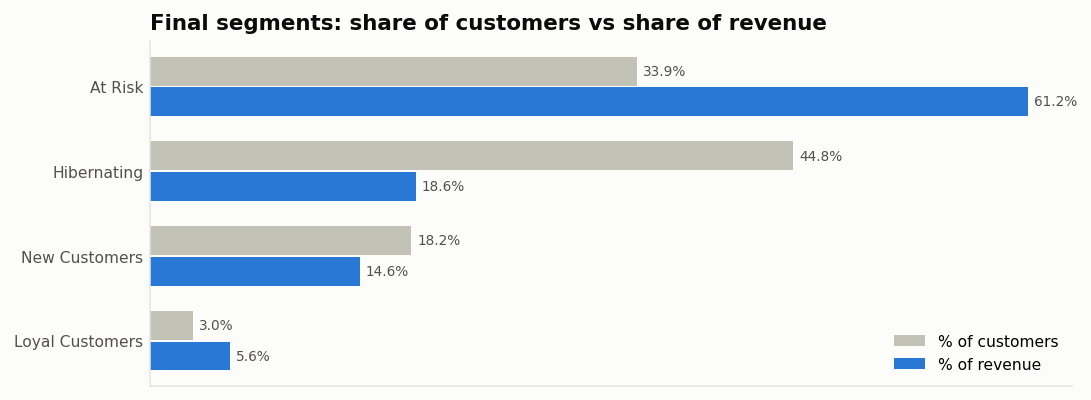

In [4]:
img('07_customer_segmentation/figures/segment_customers_vs_revenue.png', 760)

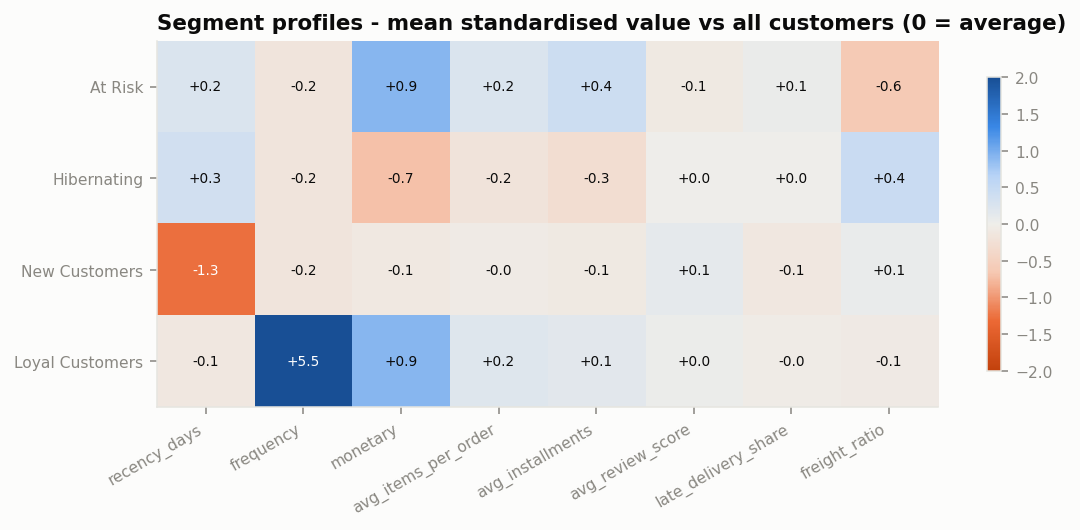

In [5]:
img('07_customer_segmentation/figures/segment_profile_heatmap.png', 820)

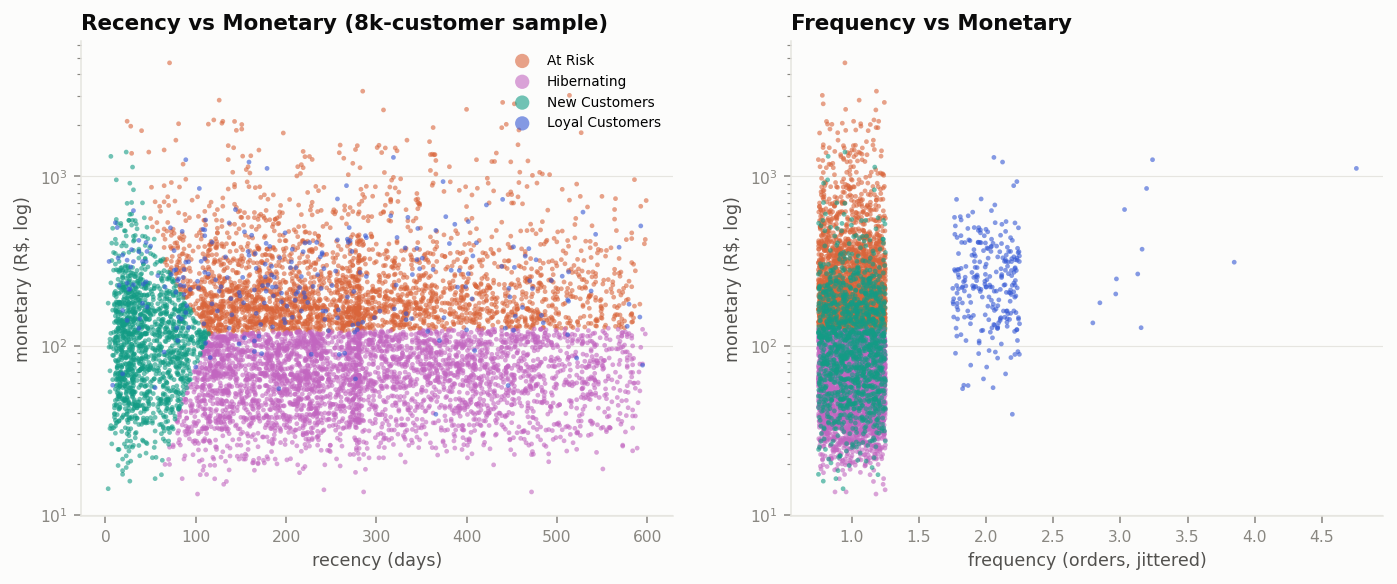

In [6]:
img('07_customer_segmentation/figures/segment_scatter.png')

In [7]:
pd.read_csv(ROOT / '07_customer_segmentation/results/segment_migration_share.csv', index_col=0).round(3)

,At Risk,Hibernating,Loyal Customers
row_0,,,
At Risk,0.968,0.023,0.009
Hibernating,0.000,0.990,0.010
Loyal Customers,0.000,0.000,1.000
New Customers,0.382,0.605,0.013
